# Lab Sheet-10 · Capstone Project 2: Disease Prediction System
**MCA III Semester (Session 2026–2027) – Capstone Machine Learning Projects**

**Objective:** predict the probable disease from patient symptoms, compare several classification algorithms, report accuracy, save the model and provide a simple prediction interface.

## Dataset (Kaggle)
[Disease Prediction Using Machine Learning (kaushil268)](https://www.kaggle.com/datasets/kaushil268/disease-prediction-using-machine-learning) – `Training.csv` (4,920 rows × 132 binary symptom columns + `prognosis`, 41 diseases) and `Testing.csv`.





## System architecture & flowchart
```
flowchart LR
    A[Kaggle CSV<br/>symptoms → disease] --> B[EDA]
    B --> C[Clean + remove duplicates<br/>prevent train/test leakage]
    C --> D[Stratified split + CV]
    D --> E[Train 8 classifiers]
    E --> F[Compare: Acc · Precision · Recall · F1]
    F --> G[Robustness test<br/>missing symptoms]
    G --> H[(Save best model<br/>disease_model.joblib)]
    H --> I[Streamlit / widget UI]
    I --> J[Top-3 probable diseases]
```

In [1]:
# !pip install -q pandas numpy matplotlib seaborn scikit-learn joblib streamlit ipywidgets
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
import os

## 1. Load data

In [2]:
DEMO = False
df = pd.read_csv("Training.csv")
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]   # stray empty column in the Kaggle file
print(df.shape)
df.head()

(4920, 133)


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


## 2. EDA

Symptom columns: 132 | diseases: 41 | nulls: 0
Duplicate rows: 4616 (94% of data)


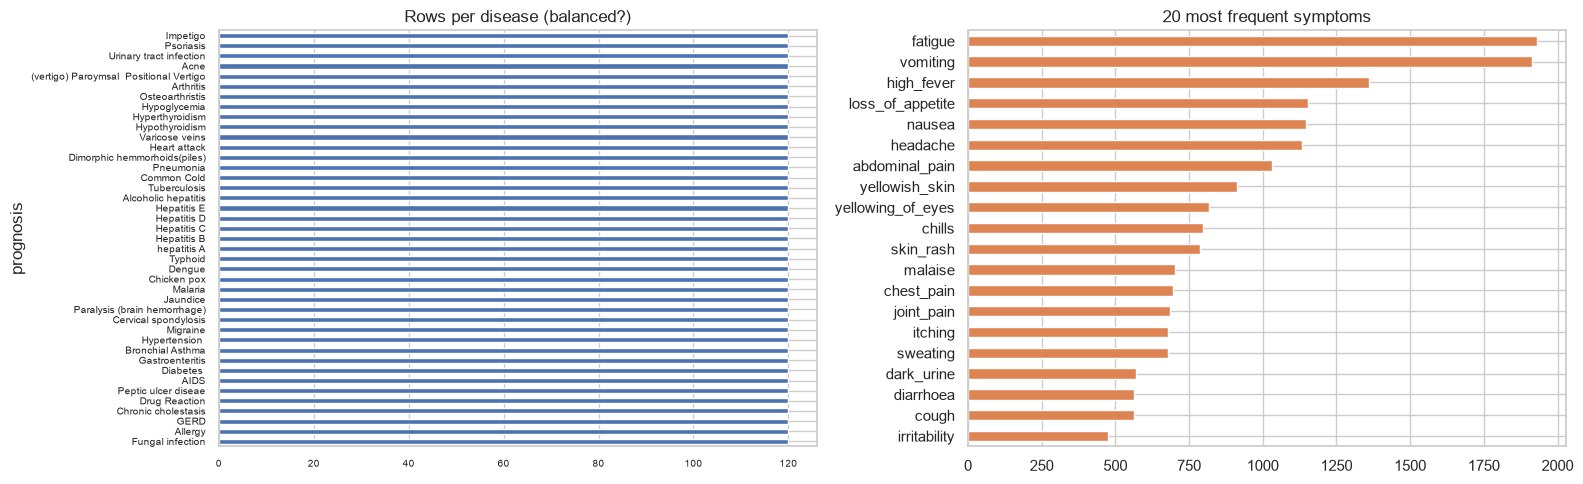

In [3]:
SYMPTOMS = [c for c in df.columns if c != "prognosis"]
print("Symptom columns:", len(SYMPTOMS), "| diseases:", df["prognosis"].nunique(), "| nulls:", int(df.isna().sum().sum()))
print("Duplicate rows:", df.duplicated().sum(), f"({df.duplicated().mean():.0%} of data)")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df["prognosis"].value_counts().sort_values().plot.barh(ax=axes[0], color="#4c72b0", fontsize=7); axes[0].set_title("Rows per disease (balanced?)")
df[SYMPTOMS].sum().nlargest(20).sort_values().plot.barh(ax=axes[1], color="#dd8452"); axes[1].set_title("20 most frequent symptoms")
plt.tight_layout(); plt.show()

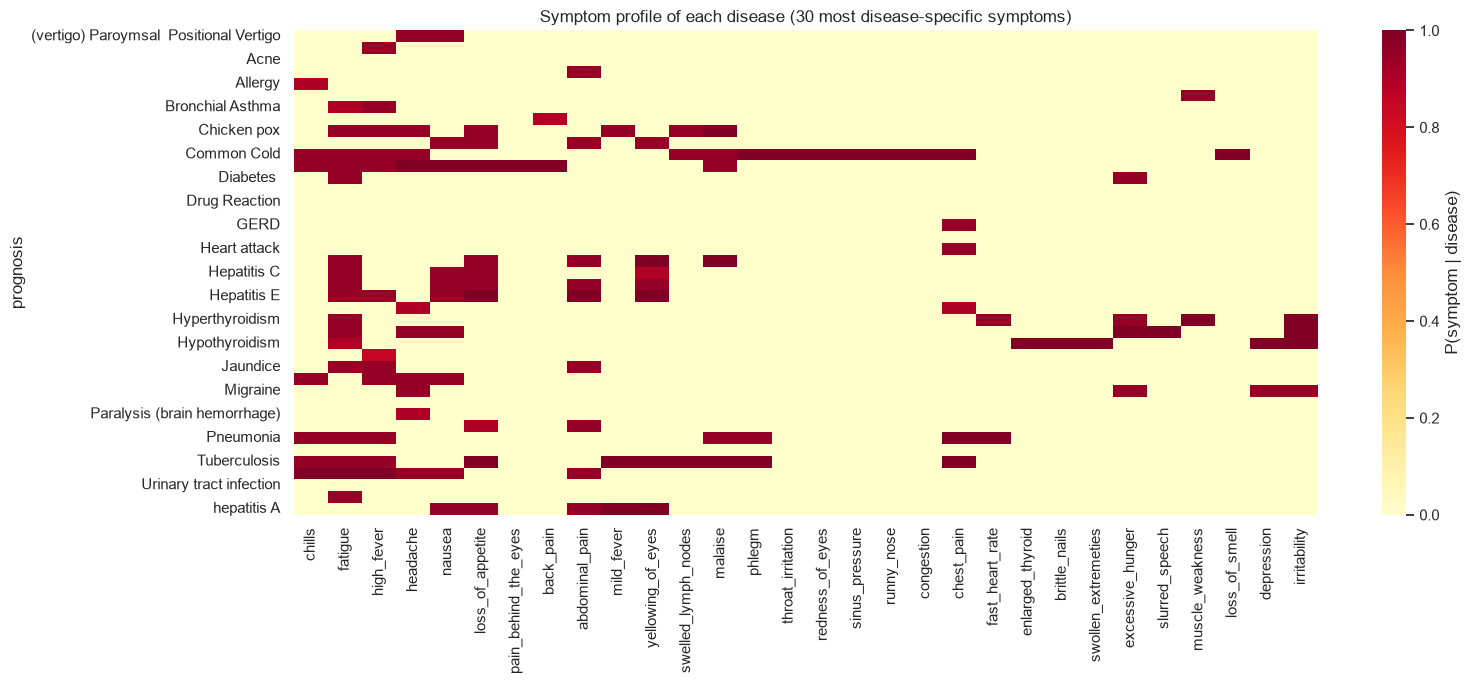

In [4]:
# Which symptoms characterise each disease? (probability of symptom given disease)
prof = df.groupby("prognosis")[SYMPTOMS].mean()
top_sym = prof.max().nlargest(30).index
plt.figure(figsize=(16, 7)); sns.heatmap(prof[top_sym], cmap="YlOrRd", cbar_kws={"label": "P(symptom | disease)"})
plt.title("Symptom profile of each disease (30 most disease-specific symptoms)"); plt.tight_layout(); plt.show()

## 3. Preprocessing
* All symptoms are binary (0/1) → no scaling/encoding needed; target is label-encoded.
* The Kaggle file contains **many duplicate rows** (each symptom pattern repeated). If duplicates are split randomly between train and test, the test set contains rows the model has already memorised → **inflated accuracy (data leakage)**. We therefore **remove duplicates before splitting** to give an honest estimate.

In [5]:
df_u = df.drop_duplicates().reset_index(drop=True)
print(f"After removing duplicates: {len(df):,} -> {len(df_u):,} rows")
le = LabelEncoder().fit(df_u["prognosis"])
X, y = df_u[SYMPTOMS].values, le.transform(df_u["prognosis"])
min_cls = np.bincount(y).min(); print("Smallest class size:", min_cls)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y if min_cls >= 2 else None, random_state=SEED)
print("train", X_train.shape, "test", X_test.shape)

After removing duplicates: 4,920 -> 304 rows
Smallest class size: 5
train (243, 132) test (61, 132)


## 4. Train & compare classifiers

,Model,Test accuracy,Precision (w),Recall (w),F1 (w),CV acc (5-fold),CV std,Train time (s)
0,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0418
1,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.5045
2,Extra Trees,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.3427
3,SVM (RBF),1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0970
4,KNN (k=5),1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0008
5,Gaussian NB,0.9836,0.9891,0.9836,0.9825,1.0000,0.0000,0.0034
6,Bernoulli NB,0.9672,0.9645,0.9672,0.9607,0.9769,0.0197,0.0045
7,Decision Tree,0.7049,0.7124,0.7049,0.6812,0.6214,0.0586,0.0059


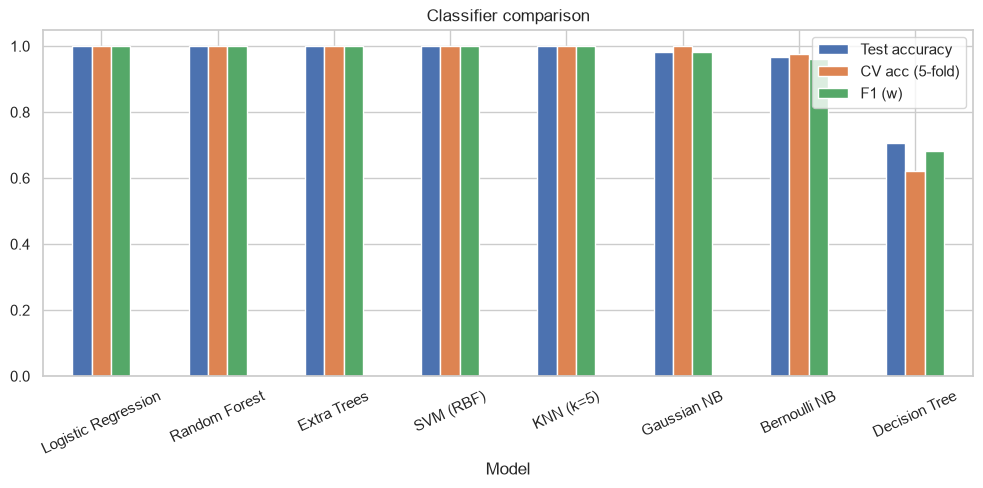

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(300, random_state=SEED, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(300, random_state=SEED, n_jobs=-1),
    "SVM (RBF)": SVC(probability=True, random_state=SEED),
    "KNN (k=5)": KNeighborsClassifier(5),
    "Bernoulli NB": BernoulliNB(),
    "Gaussian NB": GaussianNB(),
}
n_splits = int(min(5, max(2, min_cls)))
cv = StratifiedKFold(n_splits, shuffle=True, random_state=SEED)
rows, fitted = [], {}
for name, m in models.items():
    t0 = time.time(); m.fit(X_train, y_train); tt = time.time() - t0
    p = m.predict(X_test)
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, average="weighted", zero_division=0)
    cvs = cross_val_score(m, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append({"Model": name, "Test accuracy": accuracy_score(y_test, p), "Precision (w)": pr, "Recall (w)": rc, "F1 (w)": f1,
                 f"CV acc ({n_splits}-fold)": cvs.mean(), "CV std": cvs.std(), "Train time (s)": tt})
    fitted[name] = m
res = pd.DataFrame(rows).sort_values(["Test accuracy", f"CV acc ({n_splits}-fold)"], ascending=False).reset_index(drop=True)
display(res.round(4))
res.set_index("Model")[["Test accuracy", f"CV acc ({n_splits}-fold)", "F1 (w)"]].plot.bar(figsize=(12, 4.5), rot=25, title="Classifier comparison"); plt.ylim(0, 1.05); plt.show()

## 5. Detailed evaluation of the best model

Best model: Logistic Regression | test accuracy: 1.0 

                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         1
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         2
                                Allergy       1.00      1.00      1.00         1
                              Arthritis       1.00      1.00      1.00         1
                       Bronchial Asthma       1.00      1.00      1.00         1
                   Cervical spondylosis       1.00      1.00      1.00         1
                            Chicken pox       1.00      1.00      1.00         2
                    Chronic cholestasis       1.00      1.00      1.00         2
                            Common Cold       1.00   

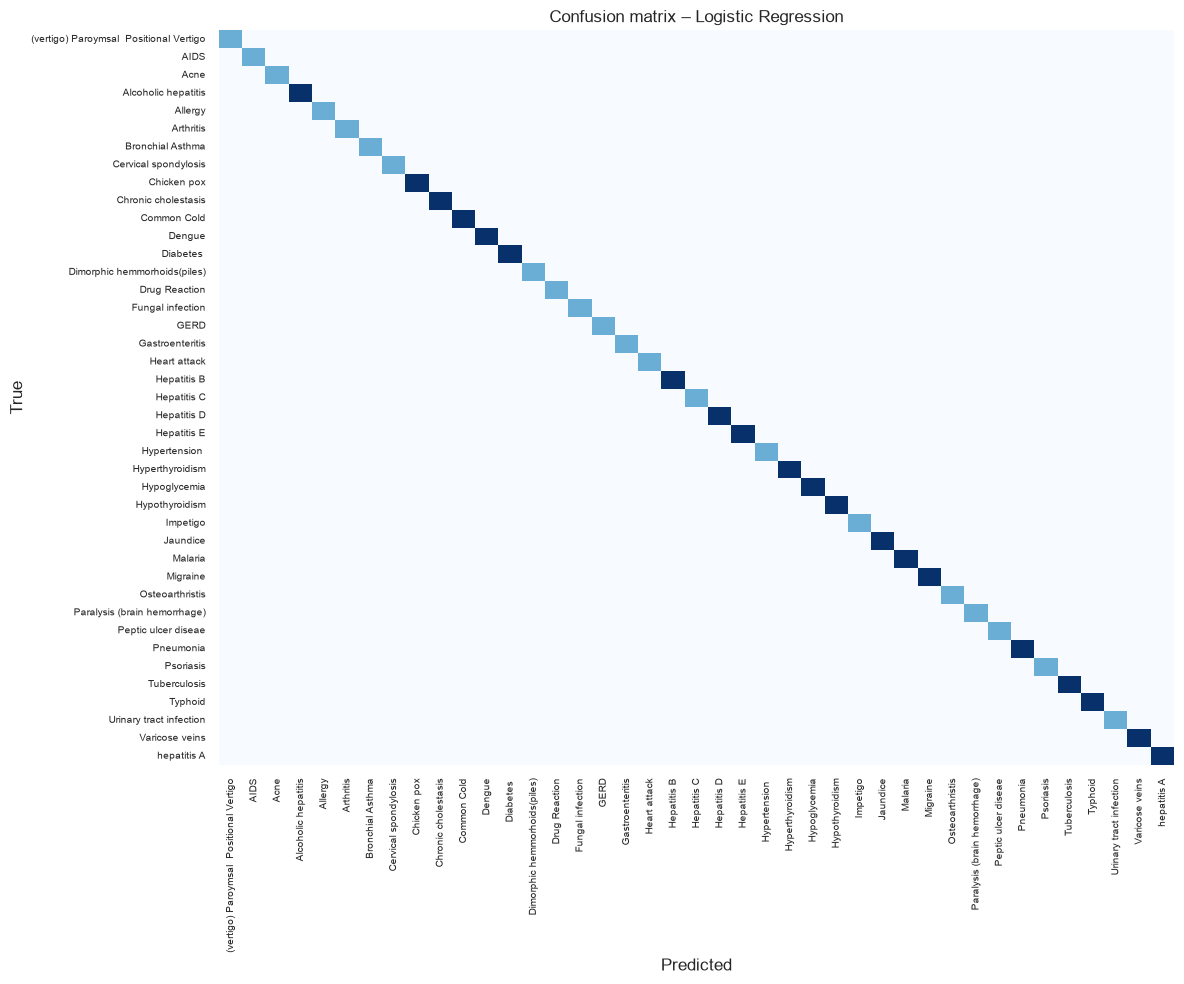

In [7]:
best_name = res.iloc[0]["Model"]; best = fitted[best_name]
pred = best.predict(X_test)
print("Best model:", best_name, "| test accuracy:", round(accuracy_score(y_test, pred), 4), "\n")
labels = np.unique(np.concatenate([y_test, pred]))
print(classification_report(y_test, pred, labels=labels, target_names=le.classes_[labels], zero_division=0))
cm = confusion_matrix(y_test, pred, labels=labels)
plt.figure(figsize=(12, 10)); sns.heatmap(cm, cmap="Blues", xticklabels=le.classes_[labels], yticklabels=le.classes_[labels], cbar=False,
                                           annot=len(labels) <= 15, fmt="d")
plt.xticks(rotation=90, fontsize=7); plt.yticks(fontsize=7); plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix – {best_name}")
plt.tight_layout(); plt.savefig("disease_confusion.png", dpi=130); plt.show()

In [8]:
if hasattr(best, "feature_importances_"):
    imp = pd.Series(best.feature_importances_, index=SYMPTOMS).nlargest(15).sort_values()
    imp.plot.barh(figsize=(8, 5), color="#55a868", title=f"Most informative symptoms ({best_name})"); plt.show()

## 6. Robustness: what if the patient reports only some symptoms?
Real users forget symptoms. We randomly **hide a fraction of the symptoms that are present** in the test set and measure accuracy.

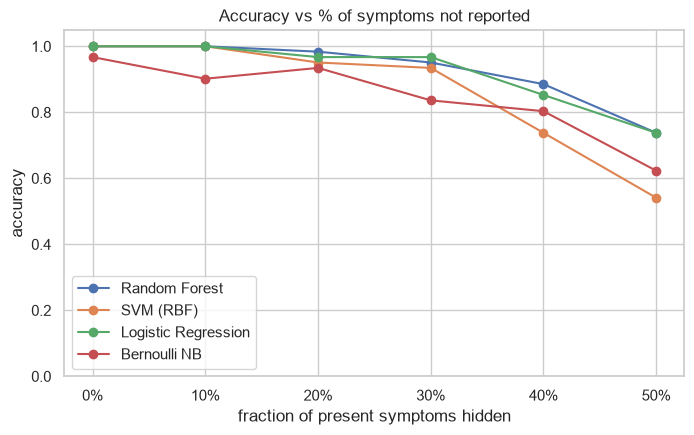

In [9]:
rng = np.random.default_rng(SEED)
fr, accs = [0, .1, .2, .3, .4, .5], {n: [] for n in ["Random Forest", "SVM (RBF)", "Logistic Regression", "Bernoulli NB"]}
for frac in fr:
    mask = (rng.random(X_test.shape) >= frac).astype(int)
    Xn = X_test * mask
    for n in accs:
        accs[n].append(accuracy_score(y_test, fitted[n].predict(Xn)))
pd.DataFrame(accs, index=[f"{int(f * 100)}%" for f in fr]).plot(marker="o", figsize=(8, 4.5), title="Accuracy vs % of symptoms not reported")
plt.xlabel("fraction of present symptoms hidden"); plt.ylabel("accuracy"); plt.ylim(0, 1.05); plt.show()

## 7. Save the final model
We train the chosen model on **all** (de-duplicated) data for deployment and save it with the symptom list and label encoder.

In [10]:
from sklearn.base import clone
final = clone(fitted[best_name]).fit(X, y)
joblib.dump({"model": final, "symptoms": SYMPTOMS, "label_encoder": le, "model_name": best_name, "demo_data": DEMO,
             "test_accuracy": float(accuracy_score(y_test, pred))}, "disease_model.joblib")
b = joblib.load("disease_model.joblib"); print("Saved disease_model.joblib | contains:", list(b))

Saved disease_model.joblib | contains: ['model', 'symptoms', 'label_encoder', 'model_name', 'demo_data', 'test_accuracy']


## 8. Prediction function & interface

In [11]:
def predict_disease(selected_symptoms, top_k=3, bundle_path="disease_model.joblib"):
    b = joblib.load(bundle_path)
    unknown = [s for s in selected_symptoms if s not in b["symptoms"]]
    if unknown:
        raise ValueError(f"Unknown symptoms: {unknown}")
    x = np.zeros((1, len(b["symptoms"])))
    for s in selected_symptoms:
        x[0, b["symptoms"].index(s)] = 1
    proba = b["model"].predict_proba(x)[0]
    idx = np.argsort(proba)[::-1][:top_k]
    return [(b["label_encoder"].classes_[i], float(proba[i])) for i in idx]


# demo: take a real row from the data and hide nothing / hide half
row = df_u.sample(1, random_state=3).iloc[0]
present = [s for s in SYMPTOMS if row[s] == 1]
print("True disease:", row["prognosis"]); print("Symptoms given:", present)
for d, p in predict_disease(present): print(f"  {d:30s} {p:6.1%}")

True disease: Hyperthyroidism
Symptoms given: ['fatigue', 'mood_swings', 'restlessness', 'sweating', 'diarrhoea', 'fast_heart_rate', 'excessive_hunger', 'muscle_weakness', 'irritability', 'abnormal_menstruation']
  Hyperthyroidism                 90.4%
  Hypoglycemia                     0.7%
  Pneumonia                        0.6%


In [12]:
try:
    import ipywidgets as w
    from IPython.display import display, clear_output
    sel = w.SelectMultiple(options=sorted(SYMPTOMS), rows=12, layout=w.Layout(width="320px"), description="Symptoms")
    btn, out = w.Button(description="Predict disease", button_style="primary"), w.Output()

    def on_click(_):
        with out:
            clear_output()
            if not sel.value:
                print("Select at least one symptom (Ctrl/Cmd-click for several)."); return
            for d, p in predict_disease(list(sel.value)): print(f"{d:30s} {p:6.1%}")
            print("\nDisclaimer: educational tool – consult a doctor.")
    btn.on_click(on_click); display(w.VBox([sel, btn, out]))
except ImportError:
    print("ipywidgets not installed – use the Streamlit app below.")

ipywidgets not installed – use the Streamlit app below.


### Streamlit web app
Run: `streamlit run app_disease.py` (needs `disease_model.joblib` in the same folder).

In [13]:
%%writefile app_disease.py
import joblib
import numpy as np
import streamlit as st

st.set_page_config(page_title="Disease Prediction", page_icon="🩺")
st.title("🩺 Disease Prediction System")
st.caption("Educational project – not a medical diagnosis.")
b = joblib.load("disease_model.joblib")
if b.get("demo_data"):
    st.warning("Model trained on synthetic demo data – retrain on the Kaggle dataset.")

picked = st.multiselect("Select the patient's symptoms",
                        sorted(b["symptoms"]), format_func=lambda s: s.replace("_", " ").title())
if st.button("Predict", type="primary"):
    if not picked:
        st.info("Please select at least one symptom.")
    else:
        x = np.zeros((1, len(b["symptoms"])))
        for s in picked:
            x[0, b["symptoms"].index(s)] = 1
        proba = b["model"].predict_proba(x)[0]
        for i in np.argsort(proba)[::-1][:3]:
            st.write(f"**{b['label_encoder'].classes_[i]}** — {proba[i]:.1%}")
            st.progress(float(proba[i]))

Writing app_disease.py


## 9. Observations
* All tree-ensemble, SVM and Naive-Bayes models separate diseases well because symptom patterns are largely disease-specific (see the profile heat-map); simple models such as Bernoulli NB are competitive and very fast.
* The raw Kaggle file contains many duplicates; **removing them before splitting** avoids the misleadingly perfect (≈100 %) accuracy that a naïve random split gives.
* Accuracy drops as more symptoms are left unreported (§6) – the system works best when the patient lists most symptoms; showing the **top-3** diseases with probabilities is safer than a single answer.
* **Limitations:** binary symptoms only (no severity, age, lab values), small number of unique symptom patterns, no clinical validation → *decision-support / educational use only*.
